# Release region

## Salinity of the ARP

In [1]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cartopy.io.shapereader as shpreader
from shapely.geometry import Polygon, box as sbox
from shapely.ops import unary_union
from matplotlib.path import Path as MplPath

In [2]:
# --- GLORYS12 / NEMO mesh ---
pathUVW = '/work/bk1450/b383184/Amazon/Mercator/data/variables/'
Hgr     = '/work/bk1450/b383184/Amazon/Mercator/data/Hgr_cmesh.nc'
Zgr     = '/work/bk1450/b383184/Amazon/Mercator/data/Zgr_cmesh2.nc'
# sal     = '/work/bk1450/b383184/Amazon/Mercator/data/variables_c/tracers/S_*'

# map window, reused everywhere
EXTENT = [-52, -46, -3, 4]

In [3]:
ss = xr.open_dataset('Sal_m_0_7m.nc').compute()
ss

<xarray.Dataset> Size: 1GB
Dimensions:  (lat: 499, lon: 1260, time: 264)
Coordinates:
  * lat      (lat) float32 2kB -9.95 -9.868 -9.785 -9.703 ... 29.77 29.84 29.91
  * lon      (lon) float32 5kB -95.0 -94.92 -94.83 -94.75 ... 9.75 9.833 9.917
  * time     (time) datetime64[ns] 2kB 1993-01-01 1993-02-01 ... 2014-12-01
Data variables:
    sal      (time, lat, lon) float64 1GB 35.74 35.74 35.74 ... nan nan nan

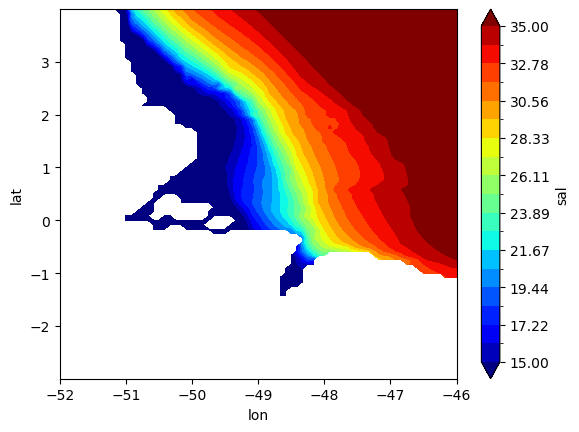

In [4]:
ss.sal.mean(dim='time').sel(lon=slice(-52,-46),lat=slice(-3,4)).plot.contourf(robust=True,cmap='jet',levels=19,vmin=15,vmax=35)
# EXTENT = [-52, -46, -3, 4]

In [5]:
s5 = ss.resample(time='1Y').mean()
s5

/work/bk1450/b383184/conda/envs/parcels_3.1.2/lib/python3.13/site-packages/xarray/groupers.py:513: FutureWarning: 'Y' is deprecated and will be removed in a future version, please use 'YE' instead.
  self.index_grouper = pd.Grouper(


<xarray.Dataset> Size: 111MB
Dimensions:  (time: 22, lat: 499, lon: 1260)
Coordinates:
  * lat      (lat) float32 2kB -9.95 -9.868 -9.785 -9.703 ... 29.77 29.84 29.91
  * lon      (lon) float32 5kB -95.0 -94.92 -94.83 -94.75 ... 9.75 9.833 9.917
  * time     (time) datetime64[ns] 176B 1993-12-31 1994-12-31 ... 2014-12-31
Data variables:
    sal      (time, lat, lon) float64 111MB 35.6 35.6 35.6 35.6 ... nan nan nan

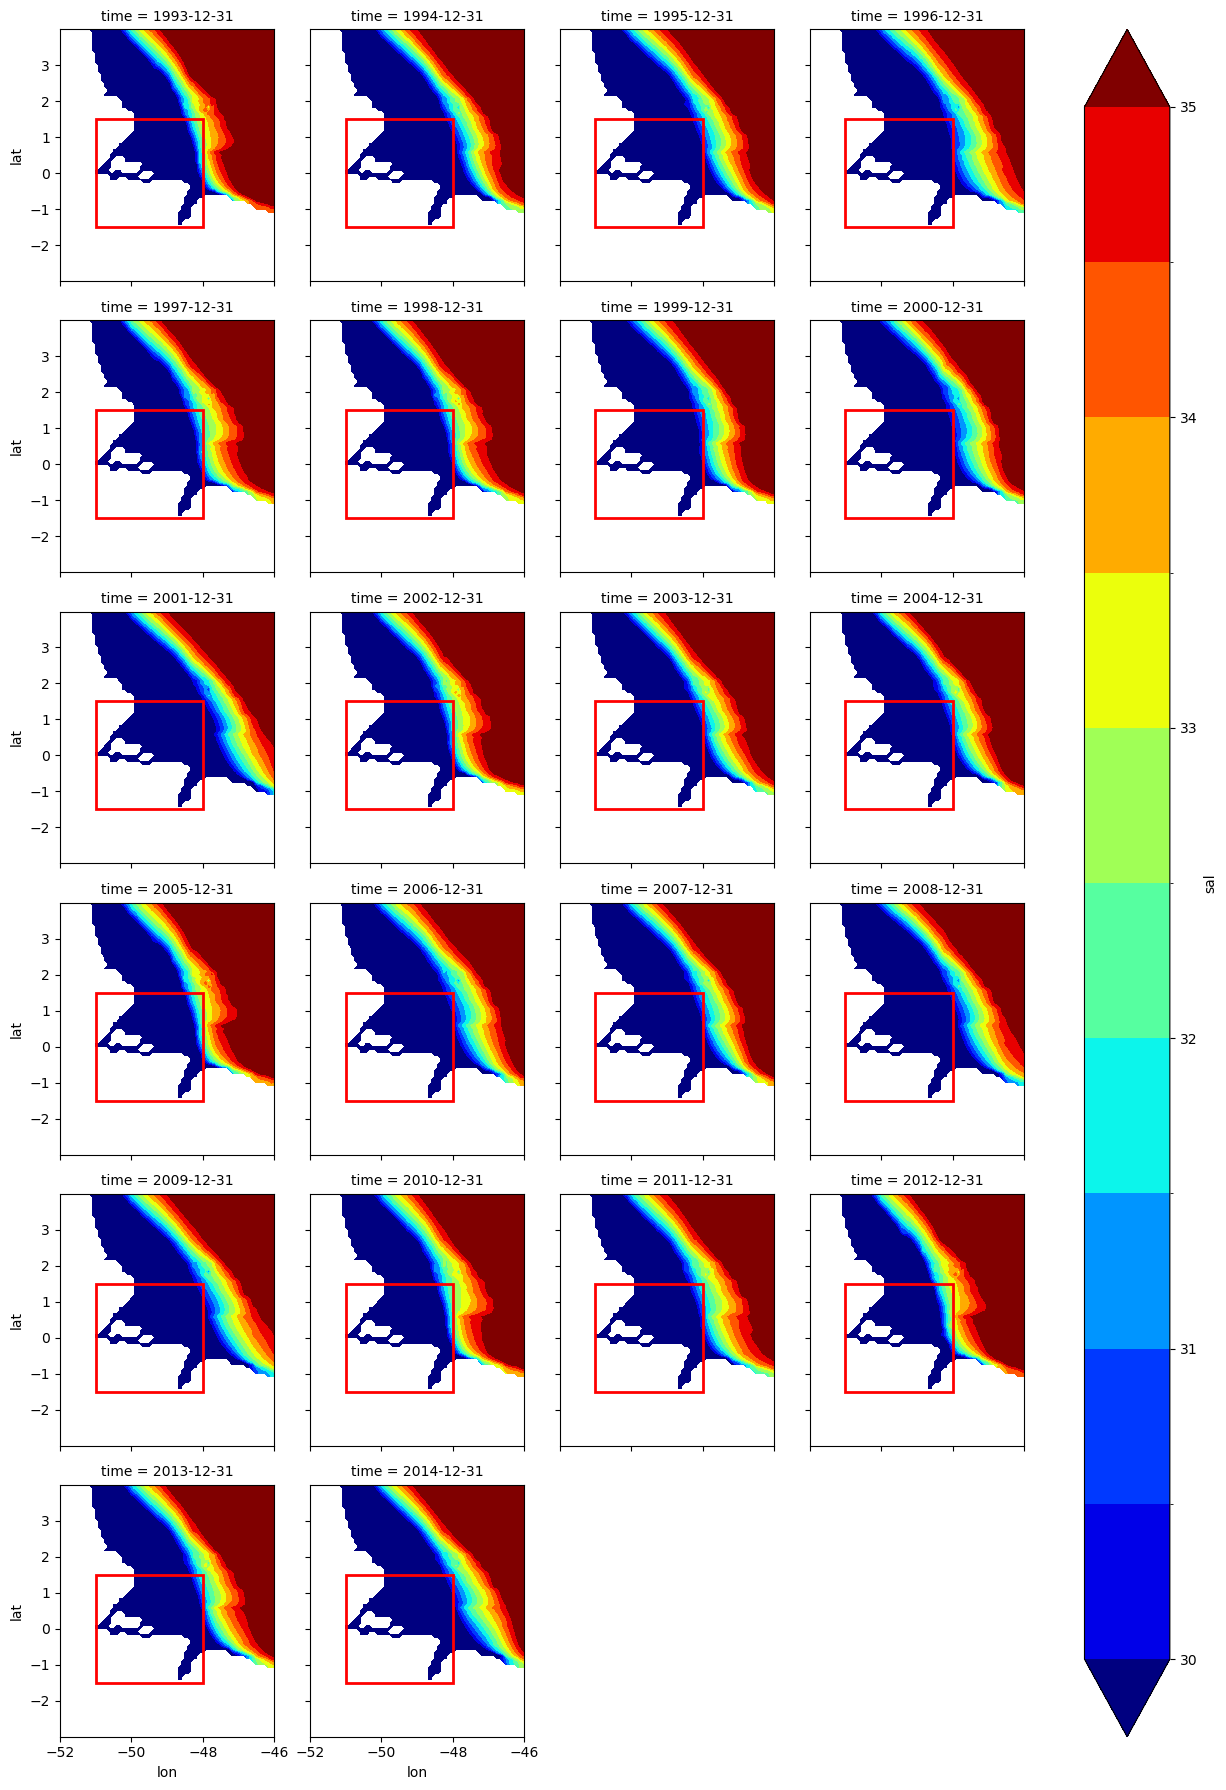

In [7]:
import matplotlib.patches as patches
g = s5.sel(lon=slice(-52,-46),lat=slice(-3,4)).sal.\
    plot.contourf(x='lon',y='lat',col='time',col_wrap=4,
                 cmap='jet',levels=11,vmin=30,vmax=35)

# Loop over all axes and add the rectangle
for ax in g.axs.flat:
    # ax.contour(sali.lon, sali.lat, sali.data, transform=ccrs.PlateCarree(),levels=[25])

    rect = patches.Rectangle((-51, -1.5), 3, 3, 
                             linewidth=2, edgecolor='r', facecolor='none')
    ax.add_patch(rect)


In [8]:
sali = ss.sal.mean(dim='time')
sali

<xarray.DataArray 'sal' (lat: 499, lon: 1260)> Size: 5MB
array([[35.42579823, 35.4273291 , 35.42898722, ..., 36.03820418,
        36.02407008, 36.00899412],
       [35.41510676, 35.41701962, 35.41893579, ..., 36.02680748,
        36.01146367, 35.99568309],
       [35.40406184, 35.4063822 , 35.40859782, ..., 36.01396891,
        35.99813105, 35.98241748],
       ...,
       [        nan,         nan,         nan, ...,         nan,
                nan,         nan],
       [        nan,         nan,         nan, ...,         nan,
                nan,         nan],
       [        nan,         nan,         nan, ...,         nan,
                nan,         nan]], shape=(499, 1260))
Coordinates:
  * lat      (lat) float32 2kB -9.95 -9.868 -9.785 -9.703 ... 29.77 29.84 29.91
  * lon      (lon) float32 5kB -95.0 -94.92 -94.83 -94.75 ... 9.75 9.833 9.917

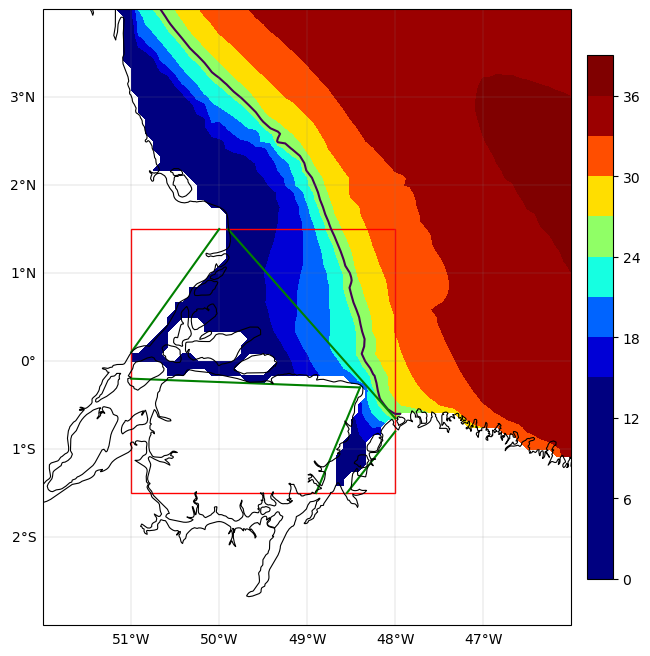

In [9]:
fig, ax = plt.subplots(figsize=(10, 8), subplot_kw=dict(projection=ccrs.PlateCarree()))
ax.set_extent(EXTENT, crs=ccrs.PlateCarree())

pc = ax.contourf(sali.lon, sali.lat, sali.data, transform=ccrs.PlateCarree(),
                   cmap='jet',levels=11,vmin=15,vmax=35)

ax.contour(sali.lon, sali.lat, sali.data, transform=ccrs.PlateCarree(),levels=[25])

ax.add_feature(cfeature.COASTLINE, linewidth=0.8, zorder=3)

gl = ax.gridlines(draw_labels=True, linewidth=0.3, color='gray', alpha=0.5)
gl.top_labels = False
gl.right_labels = False

cb = plt.colorbar(pc, ax=ax, orientation='vertical', pad=0.02, shrink=0.85,
                  )

rect = patches.Rectangle((-51, -1.5), 3, 3, linewidth=1, edgecolor='r', facecolor='none')

# Add the patch to the Axes
ax.add_patch(rect)
ax.plot([-48,-49.9],[-0.65,1.5],color='g')
ax.plot([-51,-48.4],[-0.2,-0.30],color='g')
ax.plot([-50,-51],[1.5,0.1],color='g')
ax.plot([-48.9,-48.4],[-1.5,-0.30],color='g')
ax.plot([-48,-48.55],[-0.8,-1.5],color='g')
# levels=11,vmax=35,vmin=30


In [10]:
dataC = '/work/bk1450/b383184/Amazon/Mercator/data/variables_c/'
_seed_files = {'U': ('UVW/U_1993-01c.nc', 'vozocrtx', 'deptht'), 'V': ('UVW/V_1993-01c.nc', 'vomecrty', 'deptht'),
               'W': ('UVW/W_1993-01fc.nc', 'vovecrtz', 'depthw'), 'T': ('tracers/T_1993-01c.nc', 'votemper', 'deptht'),
               'S': ('tracers/S_1993-01c.nc', 'vosaline', 'deptht')}

In [136]:
u = xr.open_dataset(dataC+'UVW/U_1993-01c.nc').isel(time_counter=0).compute()
v = xr.open_dataset(dataC+'UVW/V_1993-01c.nc').isel(time_counter=0).compute()
w = xr.open_dataset(dataC+'UVW/W_1993-01fc.nc').isel(time_counter=0).compute()
t = xr.open_dataset(dataC+'tracers/T_1993-01c.nc').isel(time_counter=0).compute()
s = xr.open_dataset(dataC+'tracers/S_1993-01c.nc').isel(time_counter=0).compute()

In [29]:
mesh = xr.open_dataset(Hgr).compute()
mesh

<xarray.Dataset> Size: 70MB
Dimensions:       (y: 499, x: 1260, z: 50, t: 1)
Dimensions without coordinates: y, x, z, t
Data variables: (12/21)
    nav_lon       (y, x) float32 3MB -95.0 -94.92 -94.83 ... 9.764 9.847 9.93
    nav_lat       (y, x) float32 3MB -9.95 -9.95 -9.95 ... 29.95 29.95 29.95
    nav_lev       (z) float32 200B 0.494 1.541 2.646 ... 5.275e+03 5.728e+03
    time_counter  (t) float64 8B 0.0
    glamt         (t, y, x) float32 3MB -95.0 -94.92 -94.83 ... 9.764 9.847 9.93
    glamu         (t, y, x) float32 3MB -94.96 -94.88 -94.79 ... 9.889 9.972
    ...            ...
    e1f           (t, y, x) float64 5MB 9.128e+03 9.128e+03 ... 8.028e+03
    e2t           (t, y, x) float64 5MB 9.127e+03 9.127e+03 ... 7.845e+03
    e2u           (t, y, x) float64 5MB 9.127e+03 9.127e+03 ... 7.845e+03
    e2v           (t, y, x) float64 5MB 9.128e+03 9.128e+03 ... 7.841e+03
    e2f           (t, y, x) float64 5MB 9.128e+03 9.128e+03 ... 7.841e+03
    ff            (t, y, x) float64 5MB -2.51e-05 -2.51e-05 ... 7.288e-05
Attributes:
    file_name:            mesh_hgr.nc
    TimeStamp:            03/02/2016 10:24:55 -0000
    Unlimited_Dimension:  t

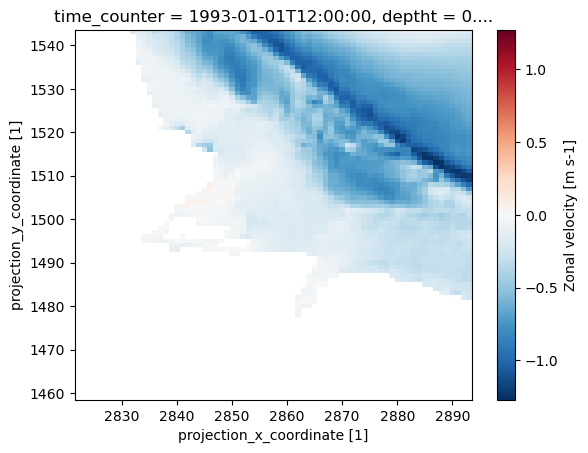

In [75]:
s = u.vozocrtx.isel(deptht=0)
s.where((s.nav_lon>=-52)&(s.nav_lon<=-46)&(s.nav_lat>=-3)&(s.nav_lat<=4), drop=True).plot()


In [115]:
nwater = u.vozocrtx.notnull().sum('deptht')
k_last = nwater - 1
k_last = k_last.where(k_last !=-1)
k_last

<xarray.DataArray 'vozocrtx' (y: 499, x: 1260)> Size: 5MB
array([[44., 44., 44., ..., 46., 46., 46.],
       [44., 44., 44., ..., 46., 46., 46.],
       [44., 45., 44., ..., 46., 46., 46.],
       ...,
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan]], shape=(499, 1260))
Coordinates:
    time_counter  datetime64[ns] 8B 1993-01-01T12:00:00
    nav_lon       (y, x) float32 3MB -94.96 -94.88 -94.79 ... 9.805 9.889 9.972
    nav_lat       (y, x) float32 3MB -9.95 -9.95 -9.95 ... 29.95 29.95 29.95
  * x             (x) float64 10kB 2.306e+03 2.307e+03 ... 3.564e+03 3.565e+03
  * y             (y) float64 4kB 1.375e+03 1.376e+03 ... 1.872e+03 1.873e+03

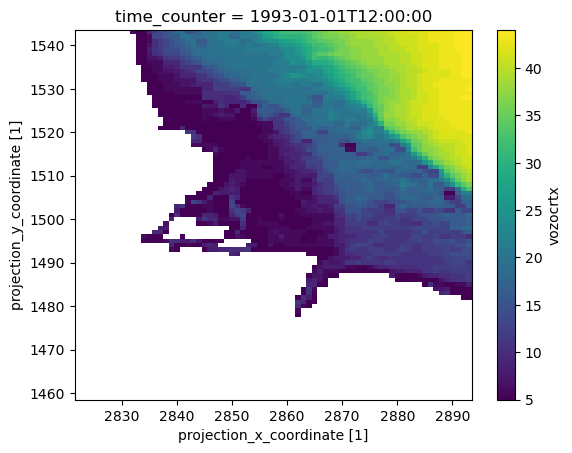

In [117]:
k_last.where((k_last.nav_lon>=-52)&(k_last.nav_lon<=-46)&(k_last.nav_lat>=-3)&(k_last.nav_lat<=4), drop=True).plot()


In [128]:
def get_water_cell(v,v_name,depth):
    
    nwater = v[v_name].notnull().sum(depth)
    k_last = nwater - 1
    k_last = k_last.where(k_last !=-1)
    return k_last

In [137]:
 # u.vozocrtx.notnull().sum('deptht')
# _seed_files = {'U': ('UVW/U_1993-01c.nc', 'vozocrtx', 'deptht'), 'V': ('UVW/V_1993-01c.nc', 'vomecrty', 'deptht'),
#                'W': ('UVW/W_1993-01fc.nc', 'vovecrtz', 'depthw'), 'T': ('tracers/T_1993-01c.nc', 'votemper', 'deptht'),
#                'S': ('tracers/S_1993-01c.nc', 'vosaline', 'deptht')}
uu = get_water_cell(u,'vozocrtx','deptht')
vv = get_water_cell(v,'vomecrty','deptht')
ww = get_water_cell(w,'vovecrtz','depthw')
tt = get_water_cell(t,'votemper','deptht')
ss = get_water_cell(s,'vosaline','deptht')


In [145]:
print(uu.shape)
print(vv.shape)
print(ww.shape)
print(tt.shape)
print(ss.shape)


(499, 1260)
(499, 1260)
(499, 1260)
(499, 1260)
(499, 1260)


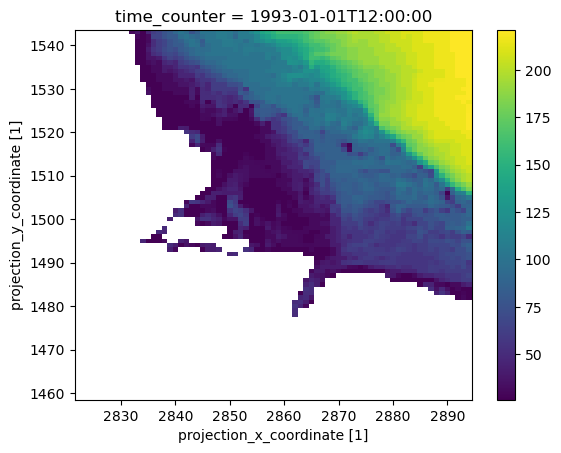

In [148]:
water_cells = (uu + vv + ww + tt + ss)
water_cells.where((water_cells.nav_lon>=-52)&(water_cells.nav_lon<=-46)
                  &(water_cells.nav_lat>=-3)&(water_cells.nav_lat<=4), drop=True).plot()

In [153]:
ARP_wc = water_cells.where((water_cells.nav_lon>=-52)&(water_cells.nav_lon<=-46)
                  &(water_cells.nav_lat>=-3)&(water_cells.nav_lat<=4), drop=True)
ARP_wc
# rect = patches.Rectangle((-51, -1.5), 3, 3, linewidth=1, edgecolor='r', facecolor='none')

<xarray.DataArray (y: 85, x: 73)> Size: 50kB
array([[ nan,  nan,  nan, ...,  nan,  nan,  nan],
       [ nan,  nan,  nan, ...,  nan,  nan,  nan],
       [ nan,  nan,  nan, ...,  nan,  nan,  nan],
       ...,
       [ nan,  nan,  nan, ..., 221., 221., 221.],
       [ nan,  nan,  nan, ..., 221., 221., 221.],
       [ nan,  nan,  nan, ..., 221., 221., 221.]], shape=(85, 73))
Coordinates:
    time_counter  datetime64[ns] 8B 1993-01-01T12:00:00
  * x             (x) float64 584B 2.822e+03 2.823e+03 ... 2.893e+03 2.894e+03
  * y             (y) float64 680B 1.459e+03 1.46e+03 ... 1.542e+03 1.543e+03
    nav_lon       (y, x) float32 25kB -52.0 -51.92 -51.83 ... -46.08 -46.0
    nav_lat       (y, x) float32 25kB -2.999 -2.999 -2.999 ... 3.997 3.997 3.997
    H             (y, x) float64 50kB 0.0 0.0 0.0 ... 3.628e+03 3.639e+03

In [155]:
ARP_wc = ARP_wc.assign_coords(x = ARP_wc.nav_lon.isel(y=0).values,
                             y = ARP_wc.nav_lat.isel(x=0).values)
ARP_wc = ARP_wc.rename(x='lon', y='lat').drop_vars(['nav_lon','nav_lat'])
ARP_wc

<xarray.DataArray (lat: 85, lon: 73)> Size: 50kB
array([[ nan,  nan,  nan, ...,  nan,  nan,  nan],
       [ nan,  nan,  nan, ...,  nan,  nan,  nan],
       [ nan,  nan,  nan, ...,  nan,  nan,  nan],
       ...,
       [ nan,  nan,  nan, ..., 221., 221., 221.],
       [ nan,  nan,  nan, ..., 221., 221., 221.],
       [ nan,  nan,  nan, ..., 221., 221., 221.]], shape=(85, 73))
Coordinates:
    time_counter  datetime64[ns] 8B 1993-01-01T12:00:00
    H             (lat, lon) float64 50kB 0.0 0.0 0.0 ... 3.628e+03 3.639e+03
  * lon           (lon) float32 292B -52.0 -51.92 -51.83 ... -46.17 -46.08 -46.0
  * lat           (lat) float32 340B -2.999 -2.915 -2.832 ... 3.83 3.914 3.997

Text(0.5, 1.0, 'Water cell number U+V+W+T+S')

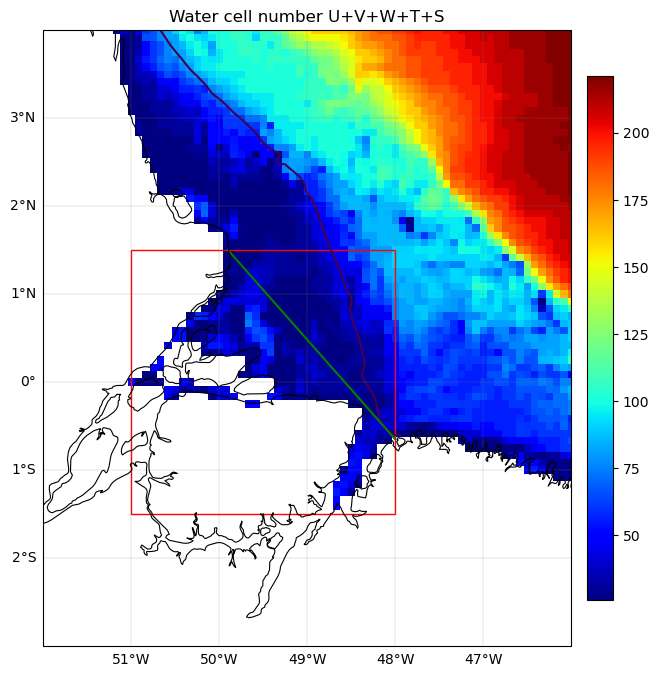

In [158]:
fig, ax = plt.subplots(figsize=(10, 8), subplot_kw=dict(projection=ccrs.PlateCarree()))
ax.set_extent(EXTENT, crs=ccrs.PlateCarree())

pc = ax.pcolormesh(ARP_wc.lon, ARP_wc.lat, ARP_wc.data, transform=ccrs.PlateCarree(),
                   cmap='jet')

ax.contour(sali.lon, sali.lat, sali.data, transform=ccrs.PlateCarree(),levels=[25])

ax.add_feature(cfeature.COASTLINE, linewidth=0.8, zorder=3)

gl = ax.gridlines(draw_labels=True, linewidth=0.3, color='gray', alpha=0.5)
gl.top_labels = False
gl.right_labels = False

cb = plt.colorbar(pc, ax=ax, orientation='vertical', pad=0.02, shrink=0.85,
                  )

rect = patches.Rectangle((-51, -1.5), 3, 3, linewidth=1, edgecolor='r', facecolor='none')

# Add the patch to the Axes
ax.add_patch(rect)
ax.plot([-48,-49.9],[-0.65,1.5],color='g')
# ax.plot([-51,-48.4],[-0.2,-0.30],color='g')
# ax.plot([-50,-51],[1.5,0.1],color='g')
# ax.plot([-48.9,-48.4],[-1.5,-0.30],color='g')
# ax.plot([-48,-48.55],[-0.8,-1.5],color='g')
# levels=11,vmax=35,vmin=30

plt.title('Water cell number U+V+W+T+S')

In [159]:
from scipy import ndimage

# water cells from the T mask only (T = cell centre; U/V are faces between cells)
T_wc = tt.where((tt.nav_lon>=-52)&(tt.nav_lon<=-46)&(tt.nav_lat>=-3)&(tt.nav_lat<=4), drop=True)
T_wc = T_wc.assign_coords(x = T_wc.nav_lon.isel(y=0).values,
                          y = T_wc.nav_lat.isel(x=0).values)
T_wc = T_wc.rename(x='lon', y='lat').drop_vars(['nav_lon','nav_lat'])

# compare with the U+V+W+T+S sum
lost = T_wc.notnull() & ARP_wc.isnull()     # water in T, but NaN in the sum

print('water cells  T mask :', int(T_wc.notnull().sum()))
print('water cells  sum    :', int(ARP_wc.notnull().sum()))
print('cells lost by sum   :', int(lost.sum()))
print('separate water regions  T mask:', ndimage.label(T_wc.notnull())[1],
      '  sum:', ndimage.label(ARP_wc.notnull())[1])

water cells  T mask : 3076
water cells  sum    : 3023
cells lost by sum   : 53
separate water regions  T mask: 1   sum: 5


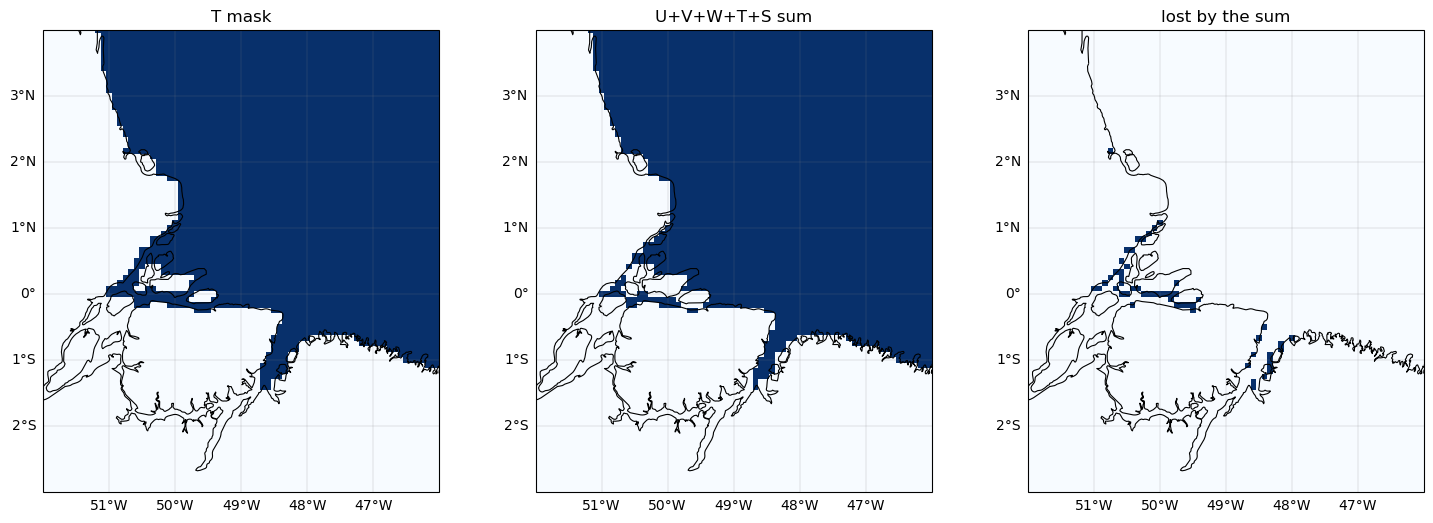

In [160]:
fig, axs = plt.subplots(1, 3, figsize=(18, 6), subplot_kw=dict(projection=ccrs.PlateCarree()))

for ax, da, title in zip(axs, [T_wc.notnull(), ARP_wc.notnull(), lost],
                         ['T mask', 'U+V+W+T+S sum', 'lost by the sum']):
    ax.set_extent(EXTENT, crs=ccrs.PlateCarree())
    ax.pcolormesh(da.lon, da.lat, da, transform=ccrs.PlateCarree(), cmap='Blues')
    ax.add_feature(cfeature.COASTLINE, linewidth=0.8, zorder=3)
    gl = ax.gridlines(draw_labels=True, linewidth=0.3, color='gray', alpha=0.5)
    gl.top_labels = False
    gl.right_labels = False
    ax.set_title(title)

Text(0.5, 1.0, 'Water cell number T_mask')

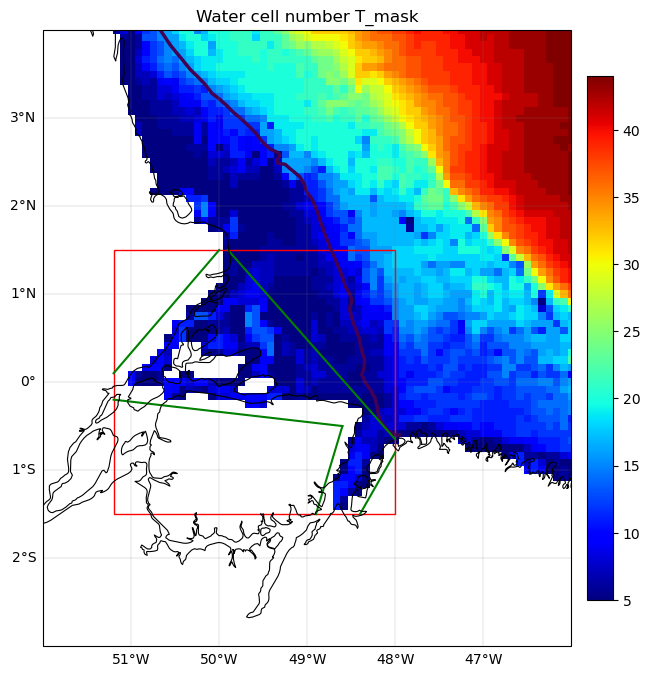

In [180]:
fig, ax = plt.subplots(figsize=(10, 8), subplot_kw=dict(projection=ccrs.PlateCarree()))
ax.set_extent(EXTENT, crs=ccrs.PlateCarree())

pc = ax.pcolormesh(T_wc.lon, T_wc.lat, T_wc.data, transform=ccrs.PlateCarree(),
                   cmap='jet')

ax.contour(sali.lon, sali.lat, sali.data, transform=ccrs.PlateCarree(),levels=[25],linewidths=2.5)

ax.add_feature(cfeature.COASTLINE, linewidth=0.8, zorder=3)

gl = ax.gridlines(draw_labels=True, linewidth=0.3, color='gray', alpha=0.5)
gl.top_labels = False
gl.right_labels = False

cb = plt.colorbar(pc, ax=ax, orientation='vertical', pad=0.02, shrink=0.85,
                  )

rect = patches.Rectangle((-51.2, -1.5), 3.2, 3, linewidth=1, edgecolor='r', facecolor='none')

# Add the patch to the Axes
ax.add_patch(rect)
ax.plot([-48,-49.9],[-0.65,1.5],color='g')
ax.plot([-51.2,-48.6],[-0.2,-0.5],color='g')
ax.plot([-50,-51.2],[1.5,0.1],color='g')
ax.plot([-48.9,-48.6],[-1.5,-0.5],color='g')
ax.plot([-48,-48.4],[-0.8,-1.5],color='g')
# levels=11,vmax=35,vmin=30

plt.title('Water cell number T_mask')

valid: True   area (deg2): 3.7375000000000043


Text(0.5, 1.0, 'Release polygon')

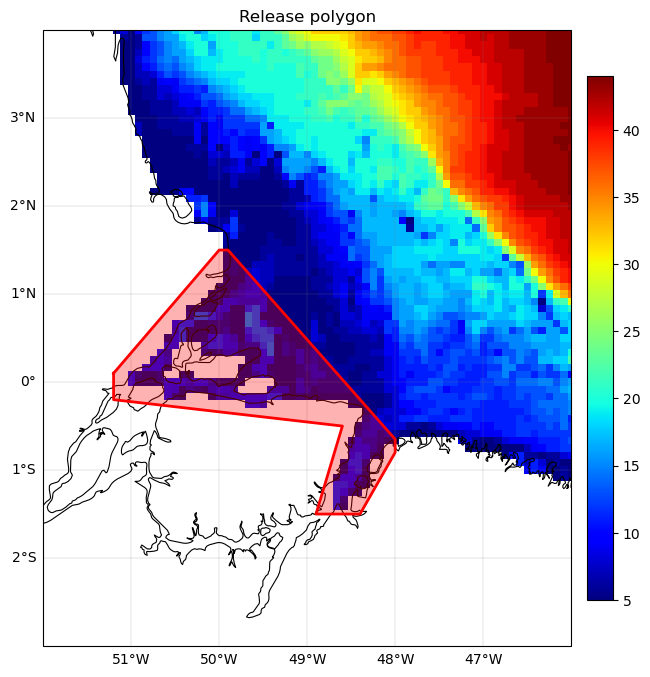

In [181]:
# release polygon = red square with the corners/pieces cut by the green lines
# vertices go clockwise, each one is a line end on the square edge (or where two lines meet)
release_poly = Polygon([
    (-51.2,  0.1 ),   # west edge  (start of NW cut line)
    (-50.0,  1.5 ),   # north edge (end of NW cut line)
    (-49.9,  1.5 ),   # north edge (start of NE cut line)
    (-48.0, -0.65),   # east edge  (end of NE cut line)
    (-48.0, -0.8 ),   # east edge  (start of SE cut line)
    (-48.4, -1.5 ),   # south edge (end of SE cut line)
    (-48.9, -1.5 ),   # south edge (start of Para line)
    (-48.6, -0.5 ),   # where the Para line meets the Marajo line
    (-51.2, -0.2 ),   # west edge  (end of Marajo line)
])
print("valid:", release_poly.is_valid, "  area (deg2):", release_poly.area)

fig, ax = plt.subplots(figsize=(10, 8), subplot_kw=dict(projection=ccrs.PlateCarree()))
ax.set_extent(EXTENT, crs=ccrs.PlateCarree())

pc = ax.pcolormesh(T_wc.lon, T_wc.lat, T_wc.data, transform=ccrs.PlateCarree(), cmap='jet')
ax.add_feature(cfeature.COASTLINE, linewidth=0.8, zorder=3)

px, py = release_poly.exterior.xy
ax.fill(px, py, color='r', alpha=0.3, transform=ccrs.PlateCarree(), zorder=4)
ax.plot(px, py, color='r', linewidth=2, transform=ccrs.PlateCarree(), zorder=4)

gl = ax.gridlines(draw_labels=True, linewidth=0.3, color='gray', alpha=0.5)
gl.top_labels = False
gl.right_labels = False
plt.colorbar(pc, ax=ax, orientation='vertical', pad=0.02, shrink=0.85)
plt.title('Release polygon')